In [1]:
import scipy
import numpy as np
import skimage
import matplotlib.pyplot as plt
import cv2

In [2]:
image_path = "https://upload.wikimedia.org/wikipedia/en/7/7d/Lenna_%28test_image%29.png"

In [3]:
from skimage import io

In [4]:
image = io.imread(image_path)

In [5]:
# image = cv2.cvtColor(cv2.imread("/home/kree/Pictures/image_samples/blueblack.jpg"), cv2.COLOR_BGR2RGB)

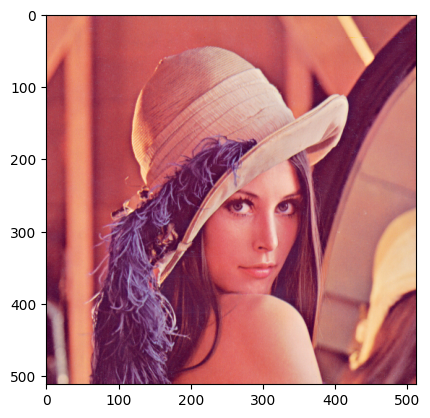

In [6]:
plt.imshow(image)
plt.show()

In [7]:
rgb_numpy = np.array(image)

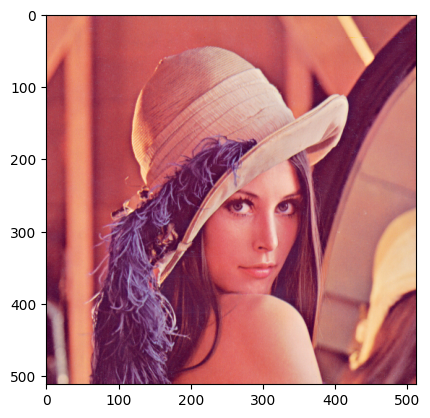

In [8]:
plt.imshow(rgb_numpy)
plt.show()

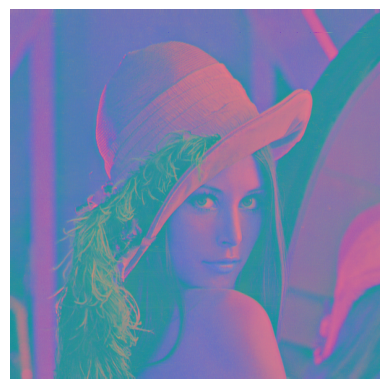

In [9]:
ygb = cv2.cvtColor(image, cv2.COLOR_BGR2YCR_CB)
plt.imshow(ygb)
plt.axis("off")
plt.show()


In [10]:
numpy_img = np.array(ygb)
numpy_img.shape

(512, 512, 3)

In [ ]:
def channel_separate(image):
    y = image[:,:,0]
    c_b = image[:,:,1]
    c_r = image[:,:,2]
    return y, c_b, c_r

In [12]:
Y, Cr, Cb = channel_separate(numpy_img)

In [13]:
print(Y.shape)

(512, 512)


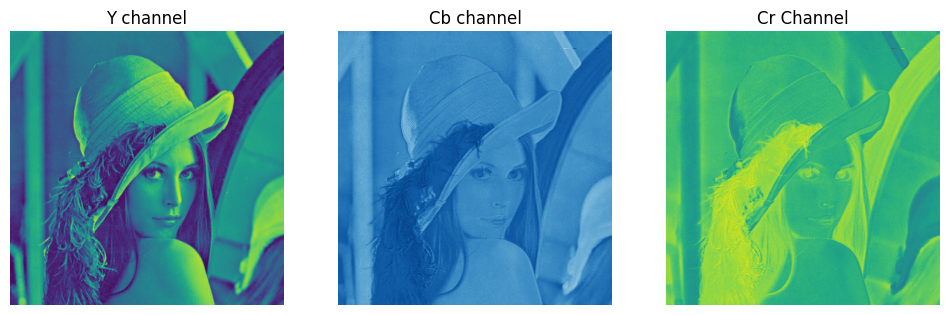

In [14]:
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)
plt.imshow(Y)
plt.title("Y channel")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(Cr, cmap="Blues")
plt.title("Cb channel")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(Cr)
plt.title("Cr Channel")
plt.axis("off")
plt.show()

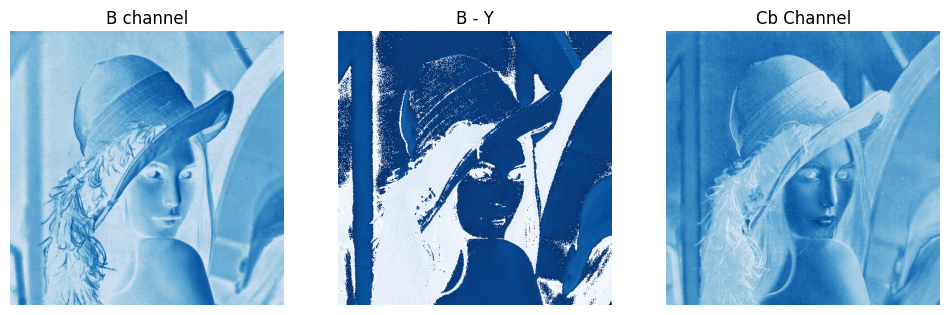

In [15]:
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)
plt.imshow(rgb_numpy[:,:,2], cmap="Blues")
plt.title("B channel")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(rgb_numpy[:,:,2] - Y, cmap="Blues")
plt.title("B - Y")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(Cb, cmap="Blues")
plt.title("Cb Channel")
plt.axis("off")
plt.show()

In [16]:
height, width, channel = numpy_img.shape
def average(image, kernel_size):
    kernel_height, kernel_width = kernel_size
    pooled = image.copy()
    for i in range(0, height, kernel_height):
        for j in range(0, width, kernel_width):
            patch = image[i:i+kernel_height, j:j+kernel_width]
            avg = np.mean(patch, dtype=np.float32)
            pooled[i:i+kernel_height, j:j+kernel_width] = avg
    return pooled.astype(image.dtype)


In [17]:
kernel = np.array([2, 2])
kernel.shape

(2,)

In [18]:
Cb_sampled = average(Cb, (2, 2))
Cr_sampled = average(Cr, (2, 2))

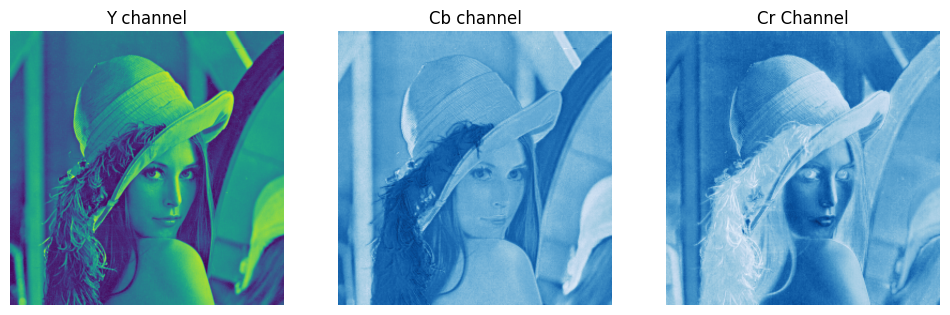

In [19]:
plt.figure(figsize=(12, 8))
plt.subplot(1, 3, 1)
plt.imshow(Y)
plt.title("Y channel")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(Cr_sampled, cmap="Blues")
plt.title("Cb channel")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(Cb_sampled,cmap="Blues")
plt.title("Cr Channel")
plt.axis("off")
plt.show()

In [20]:
Y_fb = Y[:8, :8]

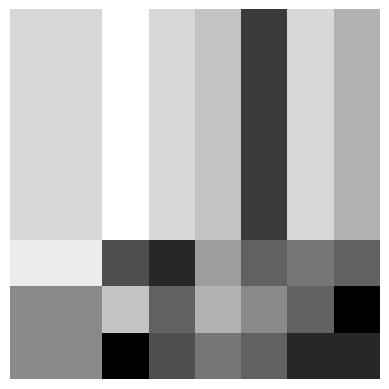

In [21]:
plt.imshow(Y[:8, :8], cmap="grey")
plt.axis("off")
plt.show()

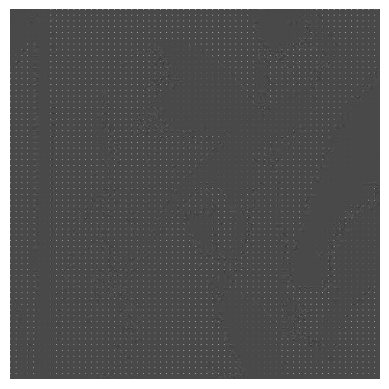

In [22]:
def dct(image):
    kernel_height = kernel_width = 8
    output = np.zeros_like(image, dtype=np.float32)
    for i in range(0, height, kernel_height):
        for j in range(0, width, kernel_width):
            patch = image[i:i+kernel_height, j:j+kernel_width]
            dct = scipy.fft.dct(scipy.fft.dct(patch.T, norm="ortho").T, norm="ortho")
            output[i:i+kernel_height, j:j+kernel_width] = dct
    return output        


Y_dct = dct(Y - 128)
plt.imshow(Y_dct, cmap="grey")
plt.axis("off")
plt.show()


/tmp/ipykernel_37856/2558580781.py:2: RuntimeWarning: invalid value encountered in log
  logged = np.log((Y_dct) + epsilon)


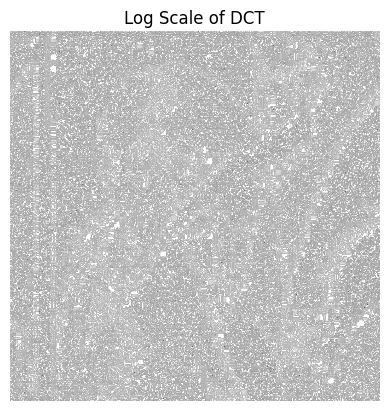

In [23]:
epsilon = 1e-8
logged = np.log((Y_dct) + epsilon)

plt.imshow(logged, cmap="grey")
plt.title("Log Scale of DCT")
plt.axis("off")
plt.show()


/tmp/ipykernel_37856/2941303869.py:3: RuntimeWarning: invalid value encountered in log
  logged_whole = np.log((dcted_whole) + epsilon)


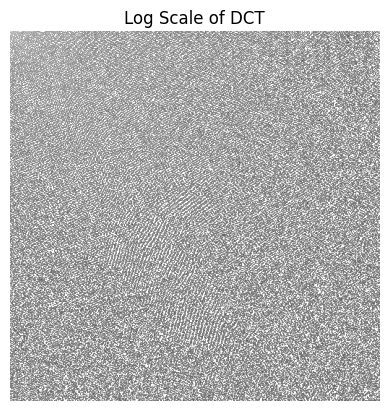

In [24]:
dcted_whole = scipy.fft.dct(scipy.fft.dct(Y.T, norm="ortho").T, norm="ortho")
epsilon = 1e-8
logged_whole = np.log((dcted_whole) + epsilon)

plt.imshow(logged_whole, cmap="grey")
plt.title("Log Scale of DCT")
plt.axis("off")
plt.show()

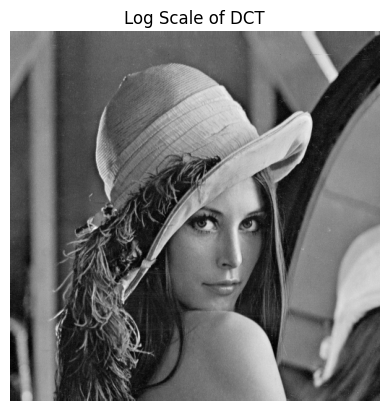

In [25]:
idct_whole = scipy.fft.idct(scipy.fft.idct(dcted_whole.T, norm="ortho").T, norm="ortho")

plt.imshow(idct_whole, cmap="grey")
plt.title("Log Scale of DCT")
plt.axis("off")
plt.show()

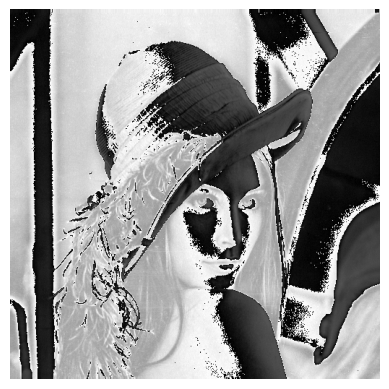

In [26]:
def idct(image):
    kernel_height = kernel_width = 8
    output = np.zeros_like(image, dtype=np.float32)
    for i in range(0, height, kernel_height):
        for j in range(0, width, kernel_width):
            patch = image[i:i+kernel_height, j:j+kernel_width]
            dct = scipy.fft.idct(scipy.fft.idct(patch.T, norm="ortho").T, norm="ortho")
            output[i:i+kernel_height, j:j+kernel_width] = dct
    return output        


inverse_Ydct = idct(Y_dct)
plt.imshow(inverse_Ydct + 128, cmap="grey")
plt.axis("off")
plt.show()


In [27]:
Q = np.array([[16, 11, 10, 16, 24, 40, 51, 61],
[12, 12, 14, 19, 26, 58, 60, 55],
[14, 13, 16, 24, 40, 57, 69, 56],
[14, 17, 22, 29, 51, 87, 80, 62],
[18, 22, 37, 56, 68, 109, 103, 77],
[24, 35, 55, 64, 81, 104, 113, 92],
[49, 64, 78, 87, 103, 121, 120, 101],
[72, 92, 95, 98, 112, 100, 103, 99]])

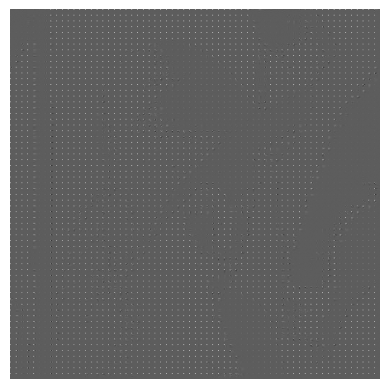

In [28]:
quantized = np.zeros_like(Y_dct)
for i in range(0, height, 8):
    for j in range(0, width, 8):
        quantized[i:i+8, j:j+8] = np.round(Y_dct[i:i+8, j:j+8] / Q)

plt.imshow(quantized, cmap="grey")
plt.axis("off")
plt.show()

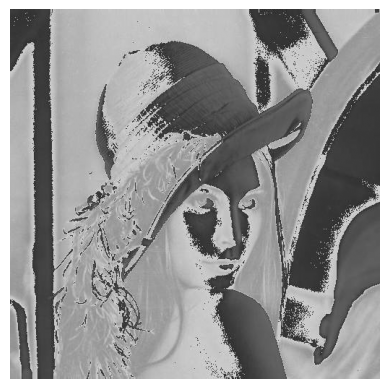

In [30]:
dequantized = np.zeros_like(Y_dct)
for i in range(0, height, 8):
    for j in range(0, width, 8):
        dequantized[i:i+8, j:j+8] = quantized[i:i+8, j:j+8] * Q

inverse_Ydct = idct(dequantized)
plt.imshow(inverse_Ydct + 128, cmap="grey")
plt.axis("off")
plt.show()

In [35]:
def jpeg_compress(img, Q, subsample=True):
    y, cb, cr = channel_separate(cv2.cvtColor(img, cv2.COLOR_BGR2YCR_CB))
    
    if subsample:
        cb = average(cb, (2, 2))
        cr = average(cr, (2, 2))
    
    y_dct = dct(y - 128)
    cb_dct = dct(cb - 128)
    cr_dct = dct(cr - 128)
    
    y_quantized = np.zeros_like(y_dct)
    cb_quantized = np.zeros_like(cb_dct)
    cr_quantized = np.zeros_like(cr_dct)
    for i in range(0, height, 8):
        for j in range(0, width, 8):
            y_quantized[i:i+8, j:j+8] = np.round(y_dct[i:i+8, j:j+8] / Q)
            cb_quantized[i:i+8, j:j+8] = np.round(cb_dct[i:i+8, j:j+8] / Q)
            cr_quantized[i:i+8, j:j+8] = np.round(cr_dct[i:i+8, j:j+8] / Q)
    
    y_dequantized = np.zeros_like(y_quantized)
    cb_dequantized = np.zeros_like(cb_quantized)
    cr_dequantized = np.zeros_like(cr_quantized)
    for i in range(0, height, 8):
        for j in range(0, width, 8):
            y_dequantized[i:i+8, j:j+8] = y_quantized[i:i+8, j:j+8] * Q
            cb_dequantized[i:i+8, j:j+8] = cb_quantized[i:i+8, j:j+8] * Q
            cr_dequantized[i:i+8, j:j+8] = cr_quantized[i:i+8, j:j+8] * Q

    y_idct = idct(y_dequantized) + 128
    cb_idct = idct(cb_dequantized) + 128
    cr_idct = idct(cr_dequantized) + 128

    compressed_y = np.clip(y_idct, 0, 255).astype(np.uint8)
    compressed_cb = np.clip(cb_idct, 0, 255).astype(np.uint8)
    compressed_cr = np.clip(cr_idct, 0, 255).astype(np.uint8)
    compressed_img = cv2.merge((compressed_y, compressed_cb, compressed_cr))

    compressed_img = cv2.cvtColor(compressed_img, cv2.COLOR_YCR_CB2BGR)
    return compressed_img


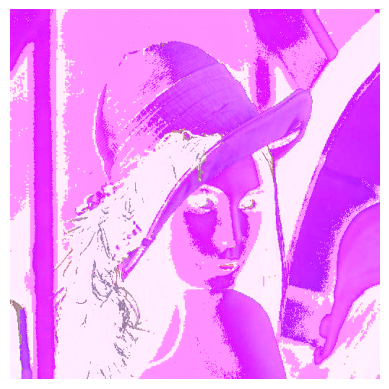

In [37]:
compressed_image = jpeg_compress(image, Q, subsample=True)
plt.imshow(compressed_image, cmap="grey")
plt.axis("off")
plt.show() 

In [29]:
PSNR, Image Original vs Compressed, File Size Comparision, SSIM, RMS error,  

SyntaxError: invalid syntax (235160311.py, line 1)

$$\text{PSNR} = 10 \cdot \log_{10}\left(\frac{MAX^2}{\text{MSE}}\right)
$$

In [ ]:
def calculate_psnr(original, compressed):
    mse = np.mean((original - compressed) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr

In [ ]:
def calculate_mse(original, compressed):
    mse = np.mean((original - compressed) ** 2)
    return mse


def file_size_calculation(image, compressed_image):
    original_size = image.nbytes
    compressed_size = compressed_image.nbytes
    return original_size, compressed_size


def ssim(original, compressed):
    from skimage.metrics import structural_similarity as ssim
    original_gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
    compressed_gray = cv2.cvtColor(compressed, cv2.COLOR_BGR2GRAY)
    return ssim(original_gray, compressed_gray)

def rms_error(original, compressed):
    return np.sqrt(np.mean((original - compressed) ** 2))